In [1]:
#ML- Miniproject Group ID 22
#BE-03-Q3
#41335 Tanisha Joshi
#41334 Aabha Jog
#41338 Gargi Kalekar

In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.neighbors import KNeighborsClassifier

In [4]:
from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score,

    confusion_matrix,

    classification_report,

    roc_auc_score,

    RocCurveDisplay

)
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

display(train_df.head())

Training Dataset Shape: (891, 12)
Testing Dataset Shape: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
print("Column Names:")
print(train_df.columns.tolist())

print("\nDataset Information:")
train_df.info()

print("\nStatistical Summary:")
display(train_df.describe())

print("\nFirst Five Records:")
display(train_df.head())

print("\nLast Five Records:")
display(train_df.tail())

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



First Five Records:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Last Five Records:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [7]:
print("Missing Values in Training Dataset:")
display(train_df.isnull().sum())

print("\nMissing Values in Testing Dataset:")
display(test_df.isnull().sum())

missing_data = pd.DataFrame({
    "Missing Count": train_df.isnull().sum(),
    "Missing Percentage": (
        train_df.isnull().mean() * 100
    ).round(2)
})

display(
    missing_data.sort_values(
        by="Missing Percentage",
        ascending=False
    )
)

Missing Values in Training Dataset:


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


Missing Values in Testing Dataset:


PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

,Missing Count,Missing Percentage
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
SibSp,0,0.00
Parch,0,0.00


In [8]:
print("Duplicate Rows in Training Dataset:",
      train_df.duplicated().sum())

print("Duplicate Rows in Testing Dataset:",
      test_df.duplicated().sum())

Duplicate Rows in Training Dataset: 0
Duplicate Rows in Testing Dataset: 0


Survival Counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival Percentages:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


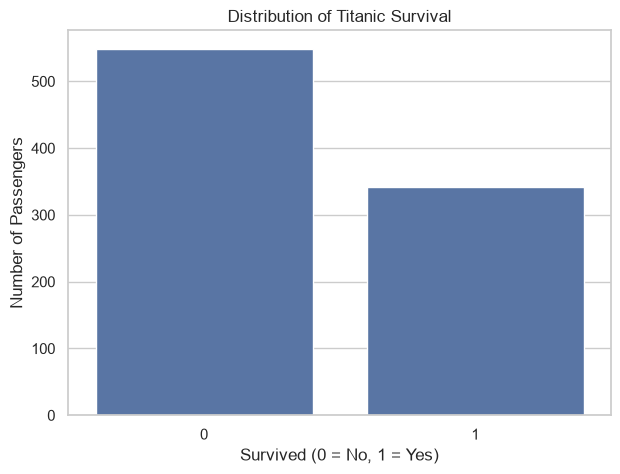

In [9]:
print("Survival Counts:")
print(train_df["Survived"].value_counts())

print("\nSurvival Percentages:")
print(
    (train_df["Survived"].value_counts(normalize=True) * 100)
    .round(2)
)

plt.figure(figsize=(7, 5))

sns.countplot(data=train_df, x="Survived")

plt.title("Distribution of Titanic Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

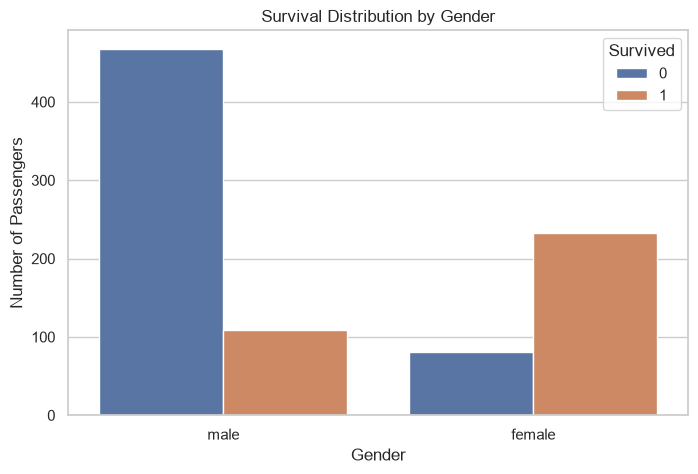

Survival Rate by Gender:


Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="Sex",
    hue="Survived"
)

plt.title("Survival Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived")

plt.show()

print("Survival Rate by Gender:")
display(
    train_df.groupby("Sex")["Survived"]
    .mean()
    .sort_values(ascending=False)
)

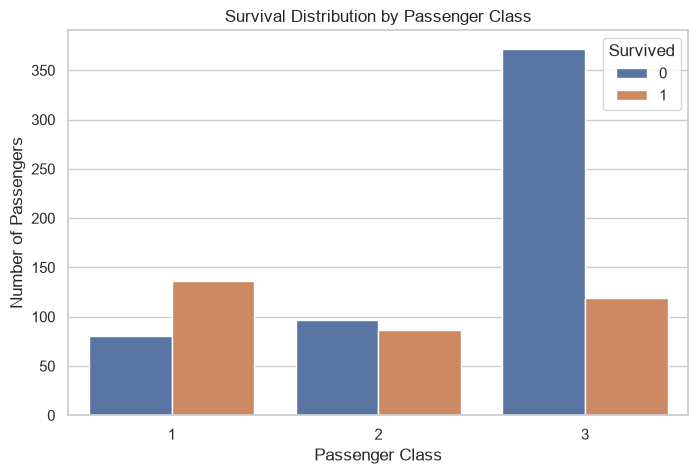

Survival Rate by Passenger Class:


Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="Pclass",
    hue="Survived"
)

plt.title("Survival Distribution by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived")

plt.show()

print("Survival Rate by Passenger Class:")
display(
    train_df.groupby("Pclass")["Survived"]
    .mean()
    .round(3)
)

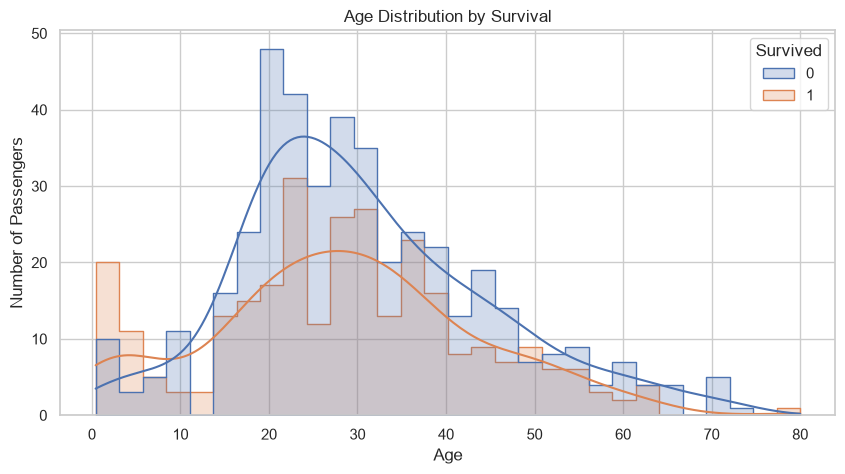

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_df,
    x="Age",
    hue="Survived",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

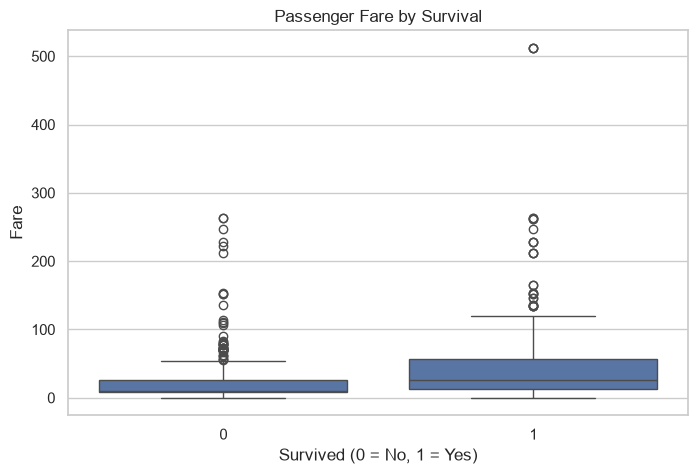

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x="Survived",
    y="Fare"
)

plt.title("Passenger Fare by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Fare")

plt.show()

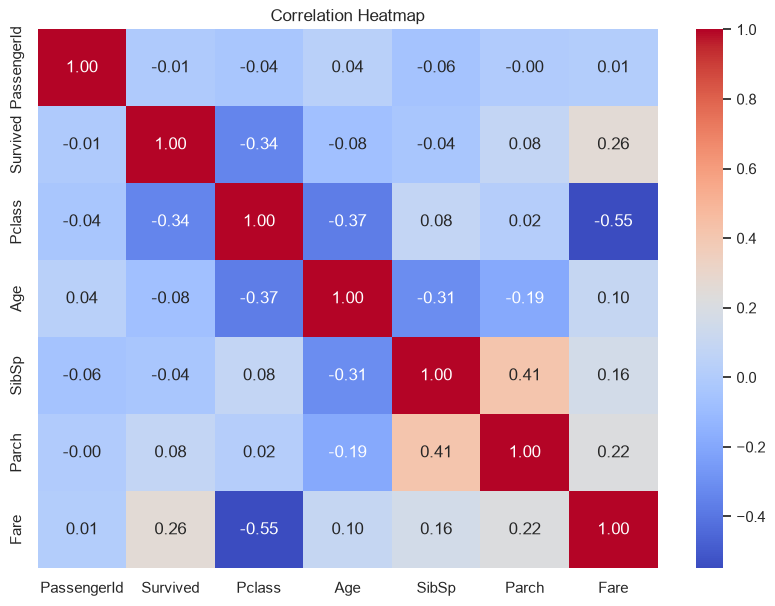

In [14]:
numeric_data = train_df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [15]:
def engineer_features(df):
    df = df.copy()

    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

    df["IsAlone"] = (
        df["FamilySize"] == 1
    ).astype(int)

    df["Title"] = (
        df["Name"]
        .str.extract(r",\s*([^.]*)\.", expand=False)
        .str.strip()
    )

    return df


train_df = engineer_features(train_df)
test_df = engineer_features(test_df)

display(
    train_df[
        ["Name", "FamilySize", "IsAlone", "Title"]
    ].head()
)

,Name,FamilySize,IsAlone,Title
0,"Braund, Mr. Owen Harris",2,0,Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",2,0,Mrs
2,"Heikkinen, Miss. Laina",1,1,Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",2,0,Mrs
4,"Allen, Mr. William Henry",1,1,Mr


In [16]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "FamilySize",
    "IsAlone",
    "Title"
]

X = train_df[features]
y = train_df["Survived"]

X_test = test_df[features]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Test Features Shape:", X_test.shape)

Features Shape: (891, 10)
Target Shape: (891,)
Test Features Shape: (418, 10)


In [17]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Validation Samples:", X_val.shape[0])

Training Samples: 712
Validation Samples: 179


In [18]:
numerical_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "IsAlone"
]

categorical_features = [
    "Pclass",
    "Sex",
    "Embarked",
    "Title"
]

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Data preprocessing pipeline created successfully!")

Data preprocessing pipeline created successfully!


In [19]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=6,
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    )
}

trained_models = {}

for model_name, classifier in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", classifier)
        ]
    )

    pipeline.fit(X_train, y_train)

    trained_models[model_name] = pipeline

    print(model_name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
K-Nearest Neighbors trained successfully!


In [20]:
results = []

for model_name, model in trained_models.items():

    y_pred = model.predict(X_val)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_pred, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8380,0.8125,0.7536,0.7820
1,K-Nearest Neighbors,0.8212,0.7937,0.7246,0.7576
2,Random Forest,0.8101,0.7869,0.6957,0.7385
3,Decision Tree,0.7933,0.8077,0.6087,0.6942


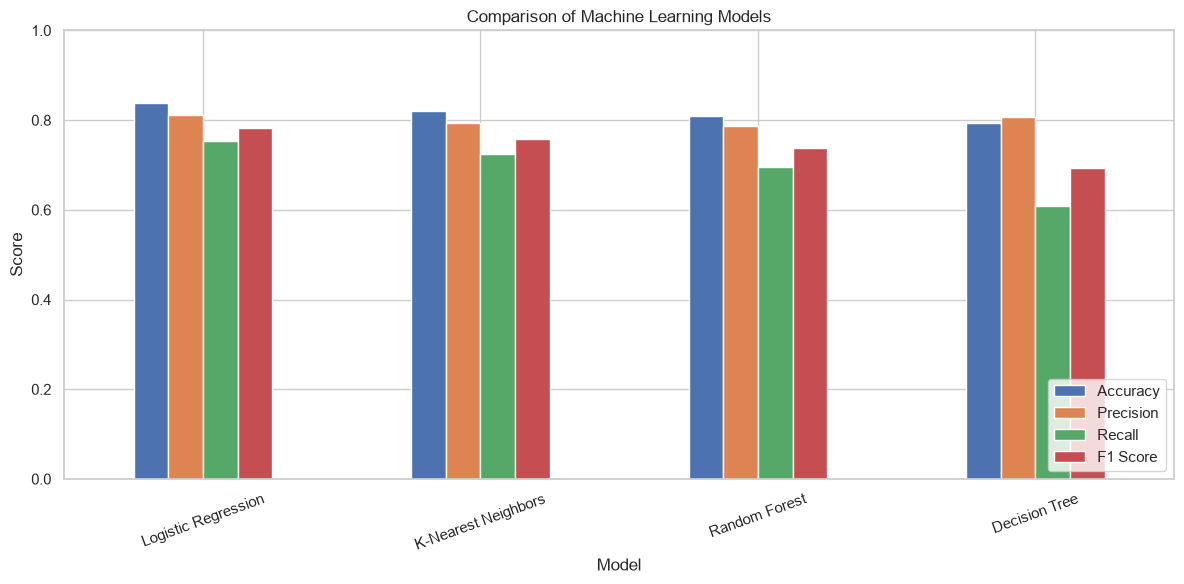

In [21]:
results_plot = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
]

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()

plt.show()

In [22]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

y_val_pred = best_model.predict(X_val)

print("Best Model Based on Validation F1 Score:",
      best_model_name)

print("\nClassification Report:\n")

print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=[
            "Did Not Survive",
            "Survived"
        ],
        zero_division=0
    )
)

Best Model Based on Validation F1 Score: Logistic Regression

Classification Report:

                 precision    recall  f1-score   support

Did Not Survive       0.85      0.89      0.87       110
       Survived       0.81      0.75      0.78        69

       accuracy                           0.84       179
      macro avg       0.83      0.82      0.83       179
   weighted avg       0.84      0.84      0.84       179



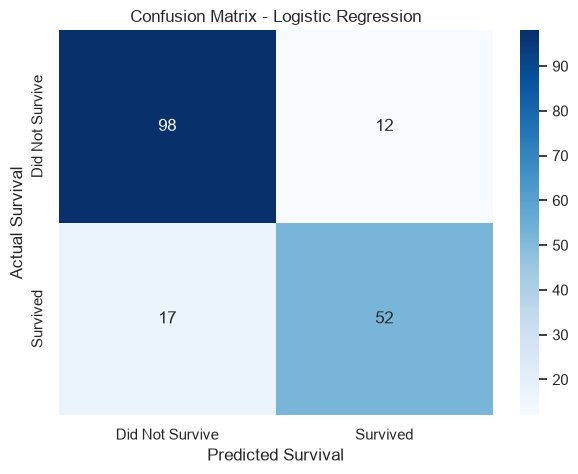

In [23]:
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Did Not Survive", "Survived"],
    yticklabels=["Did Not Survive", "Survived"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Survival")
plt.ylabel("Actual Survival")

plt.show()

ROC-AUC Score: 0.8758


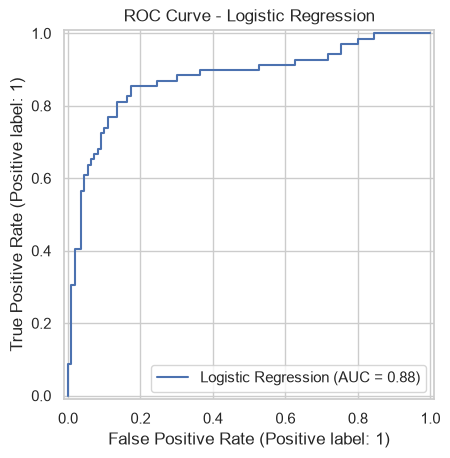

In [24]:
if hasattr(best_model, "predict_proba"):
    y_val_prob = best_model.predict_proba(X_val)[:, 1]

    auc_score = roc_auc_score(y_val, y_val_prob)

    print("ROC-AUC Score:", round(auc_score, 4))

    RocCurveDisplay.from_predictions(
        y_val,
        y_val_prob,
        name=best_model_name
    )

    plt.title(f"ROC Curve - {best_model_name}")
    plt.show()

In [25]:
cv_results = []

for model_name, classifier in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", classifier)
        ]
    )

    scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=5,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": model_name,
        "Mean CV Accuracy": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))

,Model,Mean CV Accuracy,Standard Deviation
0,Logistic Regression,0.8227,0.0229
1,Decision Tree,0.8081,0.0282
2,Random Forest,0.8271,0.0181
3,K-Nearest Neighbors,0.8149,0.0371


,Feature,Importance
23,cat__Title_Mr,0.164671
10,cat__Sex_male,0.150024
9,cat__Sex_female,0.144637
3,num__Fare,0.106049
0,num__Age,0.074712
8,cat__Pclass_3,0.062378
4,num__FamilySize,0.048882
6,cat__Pclass_1,0.045354
24,cat__Title_Mrs,0.039767
21,cat__Title_Miss,0.033368


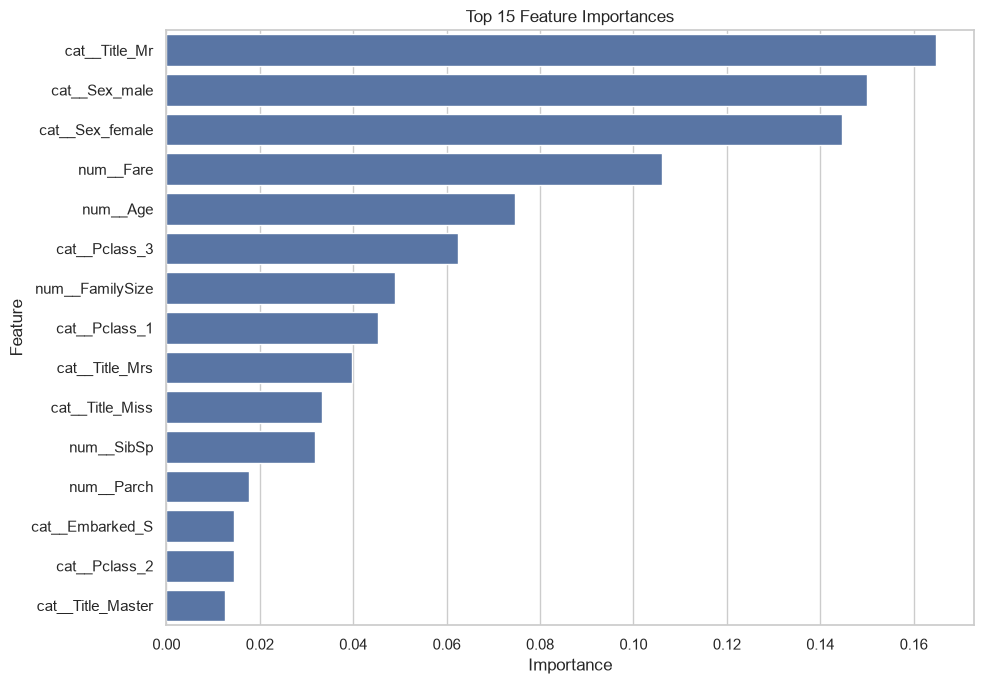

In [26]:
rf_model = trained_models["Random Forest"]

feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = rf_model.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

display(importance_df)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [27]:
final_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", models[best_model_name])
    ]
)

final_model.fit(X, y)

print("Final model trained successfully!")
print("Selected Model:", best_model_name)

Final model trained successfully!
Selected Model: Logistic Regression


In [28]:
final_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", models[best_model_name])
    ]
)

final_model.fit(X, y)

print("Final model trained successfully!")
print("Selected Model:", best_model_name)

Final model trained successfully!
Selected Model: Logistic Regression


In [29]:
test_predictions = final_model.predict(X_test)

print("Total Predictions:", len(test_predictions))

print("\nPrediction Counts:")

print(
    pd.Series(test_predictions)
    .value_counts()
    .sort_index()
)

Total Predictions: 418

Prediction Counts:
0    254
1    164
Name: count, dtype: int64


In [30]:
submission = pd.DataFrame({
    "PassengerId": test_df["PassengerId"],
    "Survived": test_predictions.astype(int)
})

display(submission.head())

submission.to_csv(
    "submission.csv",
    index=False
)

print("Submission file created successfully!")

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


Submission file created successfully!


In [31]:
assert submission.shape == (418, 2)

assert submission.columns.tolist() == [
    "PassengerId",
    "Survived"
]

assert submission["Survived"].isin([0, 1]).all()

assert submission["PassengerId"].is_unique

print("All submission checks passed!")

All submission checks passed!


In [32]:
results_df.to_csv(
    "model_comparison.csv",
    index=False
)

cv_df.to_csv(
    "cross_validation_results.csv",
    index=False
)

importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

print("Model evaluation results saved successfully!")

Model evaluation results saved successfully!


In [33]:
print("=" * 50)
print("TITANIC SURVIVAL PREDICTION")
print("=" * 50)

print("\nTraining Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

print("\nModels Evaluated:")
for model_name in trained_models:
    print("-", model_name)

print("\nBest Model:", best_model_name)

print(
    "Validation Accuracy:",
    round(
        accuracy_score(y_val, y_val_pred),
        4
    )
)

print(
    "Validation F1 Score:",
    round(
        f1_score(y_val, y_val_pred, zero_division=0),
        4
    )
)

print("\nPrediction File: submission.csv")
print("Evaluation File: model_comparison.csv")

print("\nProject execution completed successfully!")

TITANIC SURVIVAL PREDICTION

Training Dataset Shape: (891, 15)
Testing Dataset Shape: (418, 14)

Models Evaluated:
- Logistic Regression
- Decision Tree
- Random Forest
- K-Nearest Neighbors

Best Model: Logistic Regression
Validation Accuracy: 0.838
Validation F1 Score: 0.782

Prediction File: submission.csv
Evaluation File: model_comparison.csv

Project execution completed successfully!
